<a href="https://colab.research.google.com/github/quinsan7/inteligencia_artificial/blob/main/Iris_Species_com_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/menegidio/iris-species/Iris.csv
/kaggle/input/datasets/menegidio/iris-species/database.sqlite


# Iris Species com SVM - Com GridSearchCV

## Importar bibliotecas - Com GridSearchCV

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import validation_curve
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

## Carregar os dados - Com GridSearchCV

In [ ]:
df = pd.read_csv('/kaggle/input/datasets/menegidio/iris-species/Iris.csv')
df = df.drop(columns=['Id'])

print(df.shape)
print(df['Species'].value_counts())
df.head()

(150, 5)
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


## Separar X/y e treino/teste - Com GridSearchCV

In [ ]:
X = df.drop(columns=['Species'])
y = df['Species']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Treino:', X_train.shape)
print('Teste:', X_test.shape)

Treino: (120, 4)
Teste: (30, 4)


## GridSearchCV

In [ ]:
pipe_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(random_state=42))
])

param_grid_svm = {
    'svc__C': [0.1, 1, 10, 100],
    'svc__kernel': ['linear', 'rbf', 'poly'],
    'svc__gamma': ['scale', 'auto', 0.1, 1]
}

grid_svm = GridSearchCV(
    estimator=pipe_svm,
    param_grid=param_grid_svm,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_svm.fit(X_train, y_train)

print('Melhores parâmetros:', grid_svm.best_params_)
print('Melhor acurácia (validação cruzada):', round(grid_svm.best_score_, 4))

Melhores parâmetros: {'svc__C': 0.1, 'svc__gamma': 'scale', 'svc__kernel': 'linear'}
Melhor acurácia (validação cruzada): 0.975


## Acurácia e matriz de confusão - Com GridSearchCV

Acurácia treino: 0.975
Acurácia teste : 0.9333

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



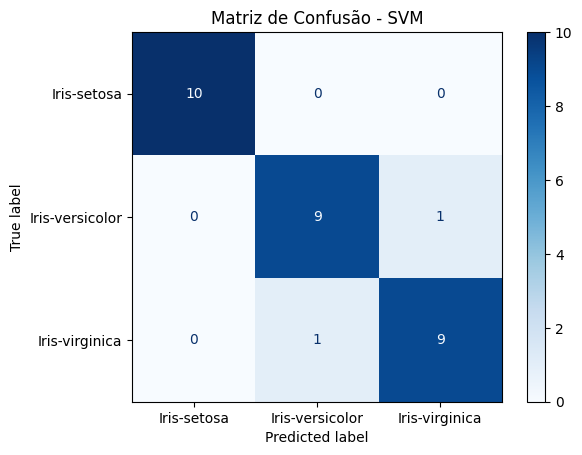

In [ ]:
best_svm = grid_svm.best_estimator_

y_pred_train_svm = best_svm.predict(X_train)
y_pred_svm = best_svm.predict(X_test)

print('Acurácia treino:', round(accuracy_score(y_train, y_pred_train_svm), 4))
print('Acurácia teste :', round(accuracy_score(y_test, y_pred_svm), 4))
print()
print(classification_report(y_test, y_pred_svm))

cm_svm = confusion_matrix(y_test, y_pred_svm, labels=best_svm.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=best_svm.classes_)
disp.plot(cmap='Blues')
plt.title('Matriz de Confusão - SVM')
plt.show()

## Análise de sensibilidade - Com GridSearchCV

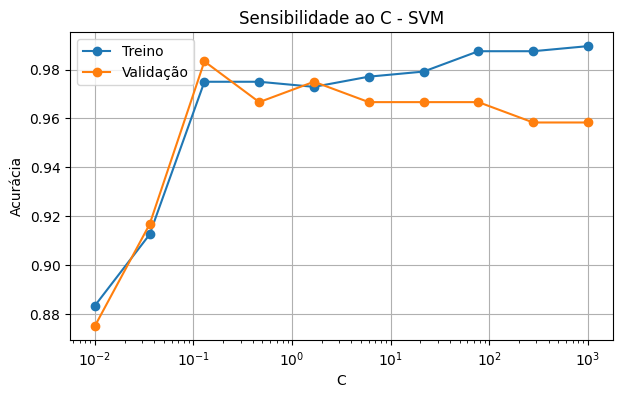

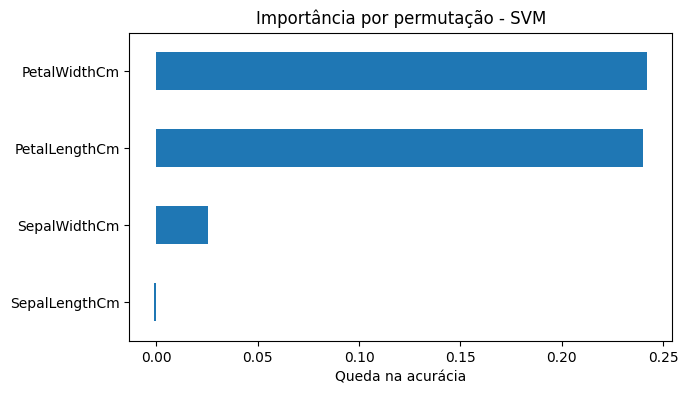

In [ ]:
param_range = np.logspace(-2, 3, 10)

train_scores, val_scores = validation_curve(
    best_svm,
    X_train,
    y_train,
    param_name='svc__C',
    param_range=param_range,
    cv=5,
    scoring='accuracy'
)

plt.figure(figsize=(7, 4))
plt.semilogx(param_range, train_scores.mean(axis=1), marker='o', label='Treino')
plt.semilogx(param_range, val_scores.mean(axis=1), marker='o', label='Validação')
plt.xlabel('C')
plt.ylabel('Acurácia')
plt.title('Sensibilidade ao C - SVM')
plt.legend()
plt.grid(True)
plt.show()

# Sensibilidade às variáveis (importância por permutação)
perm_svm = permutation_importance(
    best_svm, X_test, y_test, n_repeats=30, random_state=42, scoring='accuracy'
)

imp_svm = pd.Series(perm_svm.importances_mean, index=X.columns).sort_values()
imp_svm.plot(kind='barh', figsize=(7, 4), title='Importância por permutação - SVM')
plt.xlabel('Queda na acurácia')
plt.show()

# Iris Species com SVM - Sem GridSearchCV

## Importar bibliotecas - Sem GridSearchCV

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import validation_curve
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

## Carregar os dados - Sem GridSearchCV

In [ ]:
df = pd.read_csv('/kaggle/input/datasets/menegidio/iris-species/Iris.csv')
df = df.drop(columns=['Id'])

print(df.shape)
print(df['Species'].value_counts())
df.head()

(150, 5)
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


## Separar X/y e treino/teste - Sem GridSearchCV

In [ ]:
X = df.drop(columns=['Species'])
y = df['Species']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Treino:', X_train.shape)
print('Teste:', X_test.shape)

Treino: (120, 4)
Teste: (30, 4)


## Definir o modelo e validação cruzada - Sem GridSearchCV

In [ ]:
best_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(C=1, kernel='rbf', gamma='scale', random_state=42))
])

cv_scores = cross_val_score(best_svm, X_train, y_train, cv=5, scoring='accuracy')
print('Acurácia por fold:', np.round(cv_scores, 4))
print('Acurácia média (validação cruzada):', round(cv_scores.mean(), 4))

best_svm.fit(X_train, y_train)

Acurácia por fold: [0.9167 1.     0.9583 0.9583 1.    ]
Acurácia média (validação cruzada): 0.9667


Pipeline(steps=[('scaler', StandardScaler()),
                ('svc', SVC(C=1, random_state=42))])

## Acurácia e matriz de confusão - Sem GridSearchCV

Acurácia treino: 0.975
Acurácia teste : 0.9667

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



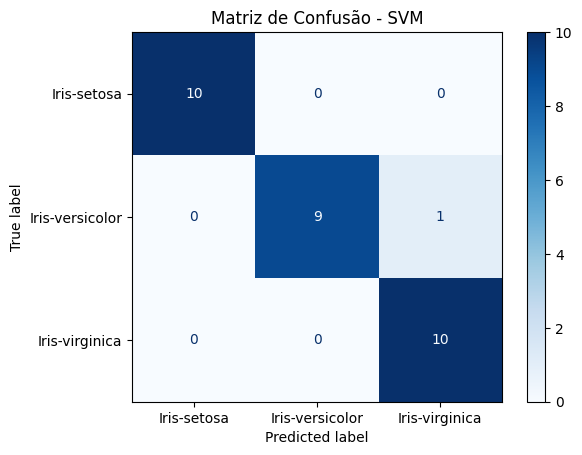

In [ ]:
y_pred_train_svm = best_svm.predict(X_train)
y_pred_svm = best_svm.predict(X_test)

print('Acurácia treino:', round(accuracy_score(y_train, y_pred_train_svm), 4))
print('Acurácia teste :', round(accuracy_score(y_test, y_pred_svm), 4))
print()
print(classification_report(y_test, y_pred_svm))

cm_svm = confusion_matrix(y_test, y_pred_svm, labels=best_svm.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=best_svm.classes_)
disp.plot(cmap='Blues')
plt.title('Matriz de Confusão - SVM')
plt.show()

## Análise de sensibilidade - Sem GridSearchCV

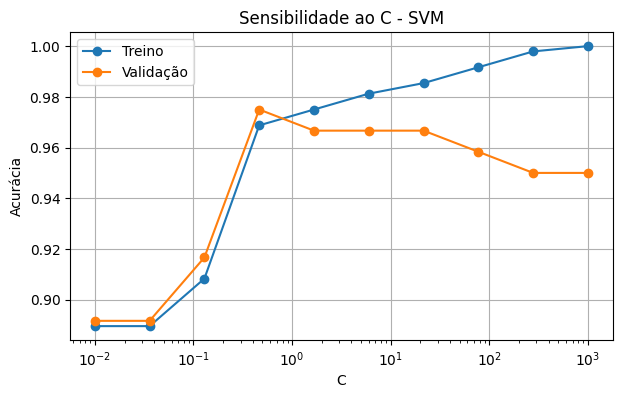

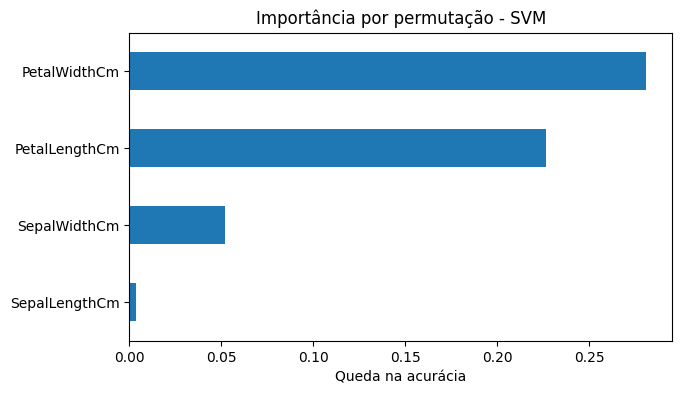

In [ ]:
param_range = np.logspace(-2, 3, 10)

train_scores, val_scores = validation_curve(
    best_svm,
    X_train,
    y_train,
    param_name='svc__C',
    param_range=param_range,
    cv=5,
    scoring='accuracy'
)

plt.figure(figsize=(7, 4))
plt.semilogx(param_range, train_scores.mean(axis=1), marker='o', label='Treino')
plt.semilogx(param_range, val_scores.mean(axis=1), marker='o', label='Validação')
plt.xlabel('C')
plt.ylabel('Acurácia')
plt.title('Sensibilidade ao C - SVM')
plt.legend()
plt.grid(True)
plt.show()

# Sensibilidade às variáveis (importância por permutação)
perm_svm = permutation_importance(
    best_svm, X_test, y_test, n_repeats=30, random_state=42, scoring='accuracy'
)

imp_svm = pd.Series(perm_svm.importances_mean, index=X.columns).sort_values()
imp_svm.plot(kind='barh', figsize=(7, 4), title='Importância por permutação - SVM')
plt.xlabel('Queda na acurácia')
plt.show()

# SVM
Sem GridSearchCV (kernel RBF, C=1, com padronização dos dados), a acurácia na validação cruzada foi de 96,67% e no teste, de 96,67%, com acurácia no treino de 97,5%, indicando boa generalização e ausência de sobreajuste. Com o GridSearchCV, o melhor modelo foi um kernel linear com C=0,1, que alcançou a maior acurácia de validação cruzada de todos os experimentos (97,50%), mas obteve 93,33% no teste. Portanto, a busca em grade melhorou o desempenho na validação e não o confirmou em dados novos, indicando que a seleção se ajustou ao processo de validação. O kernel linear escolhido também sugere que as classes do Iris são praticamente separáveis por fronteiras lineares.

# Conclusão
O Boosting e o SVM (sem GridSearchCV) tiveram os melhores resultados no Iris, ambos com 96,67% de acurácia e recall macro no teste. O Boosting teve o mesmo desempenho com e sem GridSearchCV, porque o ajuste escolheu os hiperparâmetros padrão. A Floresta Aleatória foi a que mais se beneficiou do GridSearchCV (90,00% para 96,67%). No SVM e na Árvore de Decisão, o GridSearchCV melhorou a validação cruzada, mas o teste caiu de 96,67% para 93,33%, indicando sobreajuste ao processo de seleção.

A Iris-setosa foi classificada perfeitamente por todos os modelos, e os erros ocorreram entre Versicolor e Virginica. Como o teste tem apenas 30 amostras, as diferenças correspondem a 1 ou 2 observações e devem ser interpretadas com cautela. O GridSearchCV não trouxe ganhos consistentes neste dataset.